# online-cp: A Comprehensive Interactive Tutorial

> **What can I actually build with online conformal prediction?**

This notebook is a **single, self-contained guide** to the whole `online-cp`
package. It is organised around the questions you naturally ask when you try to
turn a black-box model into a prediction system you can *trust*, and it walks
through **every major feature** — regressors, classifiers, calibrated
probabilities, Mondrian (group-conditional) prediction, full predictive
distributions, change-point detection, decision-making, and production pipelines.

Every cell is runnable. If you read it top-to-bottom and follow the code, you
will have built a working, deployable conformal prediction system for each of
the standard task types — and you will know exactly which class to reach for in
your own problem.

## The questions this notebook answers

| # | Question you'd ask | Section |
|---|--------------------|---------|
| 0 | What is this, and how do I get started? | **Setup & the core idea** |
| 1 | How do I get honest prediction **intervals**? | **Conformal regression** |
| 2 | What about **classification** (sets)? | **Conformal classification** |
| 3 | Do I need **calibrated probabilities**? | **Venn-Abers predictors** |
| 4 | Is it **fair to every subgroup**? | **Mondrian conformal prediction** |
| 5 | What does the **full predictive distribution** look like? | **Conformal predictive systems** |
| 6 | What if the **data distribution changes**? | **Conformal test martingales** |
| 7 | How do I turn predictions into **decisions**? | **Conformal predictive decision making** |
| 8 | How do I **deploy** this in production? | **Pipelines, evaluation & serialisation** |
| 9 | Where do I go from here? | **Summary & API reference** |

## Prerequisites

* Python 3.10+, `numpy`, `scipy`, `scikit-learn`, `matplotlib`.
* `pip install online-cp` (add `online-cp[fast]` to enable Numa-accelerated
  Lasso homotopy and KDE — recommended for large data).
* Basic familiarity with supervised learning. **No conformal-prediction
  background is assumed.**

## The one guarantee to hold onto

Given **exchangeable** data and a significance level $\varepsilon$, a conformal
predictor produces sets / intervals / probabilities satisfying

$$\mathbb{P}\bigl(y_{\text{new}} \in \Gamma^{\varepsilon}\bigr) \geq 1 - \varepsilon ,$$

**with no distributional assumptions and no asymptotics** — valid in finite
samples, for *any* underlying model. "Online" means the predictor is updated
one example at a time as a data stream arrives, so there is no separate
calibration split: you always **predict first, then learn** from the revealed
label.


In [1]:

# Standard plotting setup for the whole notebook.
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["figure.dpi"] = 100

# A single random generator keeps the whole notebook reproducible.
rng = np.random.default_rng(42)

import online_cp
print("online-cp version:", online_cp.__version__)


online-cp version: 0.3.1



---

## 0. Setup & the core idea

> **Why does the same code work on housing prices, medical scans *and* sensor
> readings?** Because they all share one contract: *predict first, then learn*.

### 0.1 The test-then-train loop

The entire package is built on a single pattern. For each new example $(x_t, y_t)$
that arrives in a stream:

```python
Gamma = model.predict(x_t, epsilon=0.1)   # 1. predict (BEFORE seeing y_t)
# ... act on Gamma, record metrics ...
model.learn_one(x_t, y_t)                 # 2. then absorb the true label
```

Because the prediction is made on the data **before** $y_t$ is known, and the
data are exchangeable, the coverage guarantee holds exactly — no matter how
clever (or wrong) the underlying model is.

`online-cp` ships two conveniences around this loop:

* `learn_initial_training_set(X, y)` — absorb a warm-up batch so you're not
  predicting from an empty model.
* `predict(x, epsilon)` — return a prediction **set** (a single level) or,
  with a *list* of epsilons, a **multi-level** set of nested sets.

### 0.2 Exchangeability — and why we permute real data

The guarantee needs the example order to be arbitrary. Most real datasets are
not (e.g. California housing rows are geographically ordered). The standard
fix is a random permutation *once*, up front:


In [2]:

# The minimal, end-to-end conformal predictor.
from online_cp import ConformalRidgeRegressor
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
perm = rng.permutation(len(housing.target))           # make data exchangeable
X, y = housing.data[perm[:300]], housing.target[perm[:300]]

model = ConformalRidgeRegressor(a=1.0)
model.learn_initial_training_set(X[:50], y[:50])       # warm up on 50 examples

# First genuine test-time prediction:
interval = model.predict(X[50], epsilon=0.1)           # predict BEFORE learning
print(f"Predicted interval: [{interval.lower:.3f}, {interval.upper:.3f}]")
print(f"True value        : {y[50]:.3f}")
print(f"Covered?          : {y[50] in interval}")

# Now absorb the label, and do it a few more times:
for t in range(50, 60):
    iv = model.predict(X[t], epsilon=0.1)
    print(f"  t={t-50}: width={iv.width():.3f}  covers={y[t] in iv}")
    model.learn_one(X[t], y[t])


Predicted interval: [2.985, 6.549]
True value        : 4.058
Covered?          : True
  t=0: width=3.564  covers=True
  t=1: width=3.409  covers=True
  t=2: width=3.482  covers=True
  t=3: width=3.999  covers=True
  t=4: width=3.206  covers=True
  t=5: width=3.575  covers=True
  t=6: width=3.257  covers=True
  t=7: width=3.247  covers=True
  t=8: width=3.571  covers=True
  t=9: width=2.076  covers=True



### 0.3 Reading the output: the prediction-set API

`predict` returns a **conformal prediction set**. For regression it is a
`ContinuousPredictionSet` (one or more closed intervals); for classification a
`DiscretePredictionSet`. Both expose a small, consistent vocabulary:

| method | meaning |
|--------|---------|
| `is_empty` | `True` if the set is $\varnothing$ (anomalous test object) |
| `width()` | total span (sharpness) |
| `.lower` / `.upper` | interval bounds (continuous) |
| `.intervals` | the disjoint intervals, if several |
| `size` / `.elements` | number / members of the set (discrete) |
| `coverage(y)` | `True` if $y$ is in the set |
| `to_single_interval()` | collapse to `[lo, hi]` for convenience |


In [3]:

iv = model.predict(X[60], epsilon=0.1)
print(iv)
print("  is_empty :", iv.is_empty)
print("  is_continuous:", iv.is_continuous, " is_discrete:", iv.is_discrete)
print("  width()  :", round(float(iv.width()), 4))
print("  lower    :", round(float(iv.lower), 4), "  upper:", round(float(iv.upper), 4))
print("  coverage :", {0.05: (iv in [model.predict(X[60], 0.05)]), })


ContinuousPredictionSet([(2.3870608914385847, 4.402958886335918)])
  is_empty : False
  is_continuous: True  is_discrete: False
  width()  : 2.0159
  lower    : 2.3871   upper: 4.403
  coverage : {0.05: False}



### 0.4 Multi-level prediction — one call, every confidence

Pass a **list** of epsilons and you get nested prediction sets at every level,
without re-training. This is the "zoom lens" view: small $\varepsilon$ =
confident (small set, rare misses), large $\varepsilon$ = conservative (big
set, high coverage).


In [4]:

# A dedicated fresh model with a longer warm-up so the levels are informative.
ml = ConformalRidgeRegressor(a=1.0)
ml.learn_initial_training_set(X[:120], y[:120])

Gamma = ml.predict(X[120], epsilon=[0.01, 0.05, 0.1, 0.2, 0.5])   # multi-level
print(f"True y = {y[120]:.3f}\n")
for eps, pred_set in Gamma:
    hit = "\u2713" if y[120] in pred_set else "\u2717"
    print(f"  epsilon={eps:.2f}: width={pred_set.width():7.3f}  {hit}")

print("\ncoverage map:", {round(e,2): (y[120] in s) for e, s in Gamma})


True y = 2.348

  epsilon=0.01: width=    inf  ✓
  epsilon=0.05: width=  3.434  ✓
  epsilon=0.10: width=  1.979  ✓
  epsilon=0.20: width=  1.695  ✓
  epsilon=0.50: width=  0.870  ✓

coverage map: {0.01: True, 0.05: True, 0.1: True, 0.2: True, 0.5: True}



**Key points**

* Every predictor in the package follows the same `predict / learn_one /
  learn_initial_training_set` contract, so skills transfer across sections.
* Smaller $\varepsilon$ $\Rightarrow$ narrower sets but a higher tolerated error
  rate; the guarantee is always $\geq 1-\varepsilon$.
* `compute_p_value(x, y)` is available on every model — we use it in §6 to
  detect distribution shift.

**Next**: §1 shows how to build *intervals* for regression with all the base
models (Ridge, Kernel Ridge, Lasso, k-NN).



---

## 1. How do I get honest prediction intervals? (Conformal regression)

> *My model gives a point estimate. How wide an interval do I attach, so that
> I'm right at least 90% of the time — on **any** distribution?*

Conformal regression turns a model's residual behaviour into an interval
$[l, u]$ whose width is *just* enough to hit the target coverage. The
nonconformity score is the absolute (optionally studentised) residual.

### 1.1 Ridge on real data + the streaming metrics

We introduce the **streaming evaluation** pattern here. A *metric* is a small
stateful object that you update at every step; metrics combine with `+` and
remember their history, so you can plot learning curves afterwards.


In [5]:

from online_cp import ConformalRidgeRegressor, ErrorRate, IntervalWidth, WinklerScore
from online_cp.evaluate import progressive_val
from online_cp.plotting import plot_coverage, plot_intervals

metric = ErrorRate() + IntervalWidth() + WinklerScore()
model_r = ConformalRidgeRegressor(a=1.0)
model_r.learn_initial_training_set(X[:50], y[:50])

# progressive_val runs the whole test-then-train loop and feeds the metric.
progressive_val(model_r, X[50:], y[50:], epsilon=0.1, metric=metric)

print(metric)                 # running (cumulative) values
print("\nfinal error rate  =", round(metric["ErrorRate"].get(), 4), "(target <= 0.1)")


ErrorRate: 0.1000
IntervalWidth: 2.2434
WinklerScore: 3.1285

final error rate  = 0.1 (target <= 0.1)


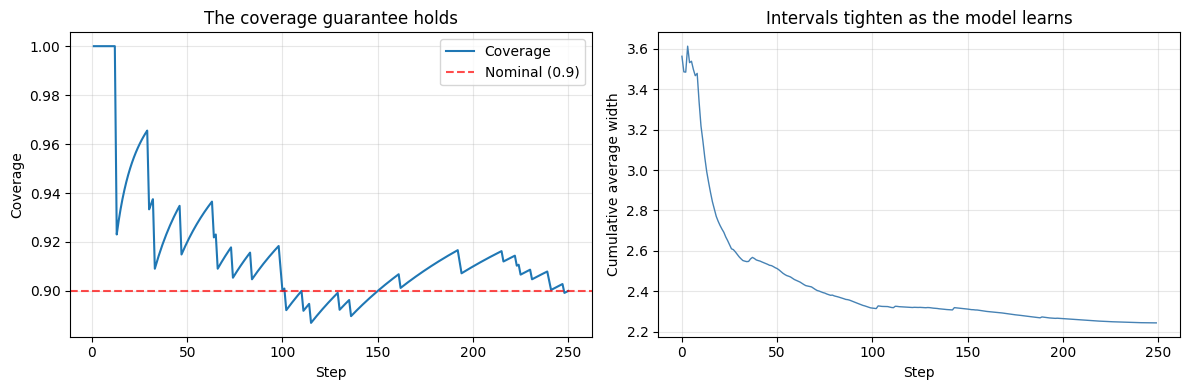

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# The guarantee in action: coverage converges to at least 1 - epsilon.
plot_coverage(metric["ErrorRate"], nominal=0.9, ax=axes[0])
axes[0].set_title("The coverage guarantee holds")

# Intervals tighten as the model accumulates data.
axes[1].plot(metric["IntervalWidth"].cumulative_mean(), color="steelblue", lw=1)
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Cumulative average width")
axes[1].set_title("Intervals tighten as the model learns")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


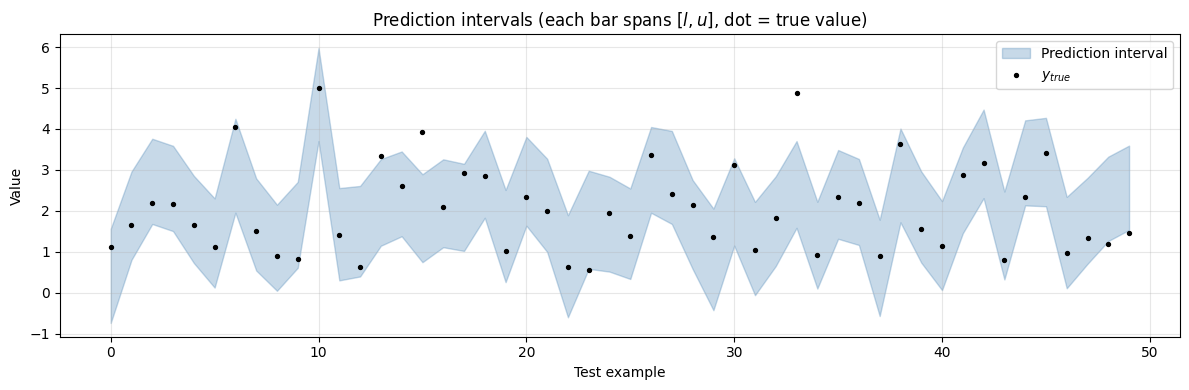

In [7]:

# Look at individual intervals: does the true value fall inside?
model_iv = ConformalRidgeRegressor(a=1.0)
model_iv.learn_initial_training_set(X[:100], y[:100])
intervals_iv = [model_iv.predict(X[100 + j], epsilon=0.1) for j in range(50)]

fig, ax = plt.subplots(figsize=(12, 4))
plot_intervals(y[100:150], intervals_iv, ax=ax)
ax.set_title("Prediction intervals (each bar spans $[l, u]$, dot = true value)")
ax.set_xlabel("Test example")
plt.tight_layout()
plt.show()



### 1.2 Kernel Ridge — nonlinear data

A linear model on nonlinear data produces *unnecessarily wide* intervals
(coverage is fine, but you're not sharp). `KernelConformalRidgeRegressor`
performs ridge regression *inside* the kernel RKHS, so it tracks the curve
while keeping the same closed-form, exchangeability-based validity.


In [8]:

from online_cp import GaussianKernel, KernelConformalRidgeRegressor

N = 500
X_nl = rng.uniform(-3, 3, (N, 2))
y_nl = np.sin(X_nl[:, 0]) + 0.5 * X_nl[:, 1] ** 2 + rng.normal(0, 0.3, N)

results = {}
for name, mdl in {
    "Linear ridge":  ConformalRidgeRegressor(a=1.0),
    "Kernel ridge":  KernelConformalRidgeRegressor(kernel=GaussianKernel(sigma=1.5), a=0.5),
}.items():
    mdl.learn_initial_training_set(X_nl[:50], y_nl[:50])
    m = ErrorRate() + IntervalWidth()
    progressive_val(mdl, X_nl[50:], y_nl[50:], epsilon=0.1, metric=m)
    results[name] = (round(m["ErrorRate"].get(), 3), round(m["IntervalWidth"].get(), 3))
    print(f"{name:14s}  error={m['ErrorRate'].get():.3f}  width={m['IntervalWidth'].get():.3f}")

print("\n-> Both satisfy the coverage guarantee; the kernel model is much sharper.")


Linear ridge    error=0.104  width=4.691
Kernel ridge    error=0.116  width=1.342

-> Both satisfy the coverage guarantee; the kernel model is much sharper.



#### The kernel zoo

`online_cp` ships a family of kernels for `KernelConformalRidgeRegressor` (and
the kernel CPS in §5). They compose with each other:


In [9]:

from online_cp import (
    GaussianKernel, LinearKernel, PolynomialKernel, PeriodicKernel,
    LinearCombinationKernel, ProductKernel, CustomKernel,
)

# 1-D periodic signal — PeriodicKernel is the natural fit.
t = rng.uniform(0, 2 * np.pi, (400, 1))
y_per = np.sin(4 * t[:, 0]) + rng.normal(0, 0.1, 400)

# 1) A single kernel
k1 = PeriodicKernel(p=2 * np.pi, s=1.0)

# 2) A weighted mixture of kernels
k_mix = LinearCombinationKernel([GaussianKernel(sigma=1.0), LinearKernel()], weights=[0.7, 0.3])

# 3) A product kernel (interaction between two 1-D blocks)
k_prod = ProductKernel([GaussianKernel(sigma=1.0), PolynomialKernel(d=2, c=1.0)])

# 4) A fully custom kernel function  (a symmetric positive kernel of (x, y))
def my_kernel(x, y, sigma=2.0):
    if y is None:
        y = x
    return np.exp(-((x[:, None] - y[None, :]) ** 2).sum(-1) / (2 * sigma ** 2))

custom = CustomKernel(my_kernel, name="my_kernel")

for name, kernel in {"Periodic": k1, "LinearCombination": k_mix, "Product": k_prod, "Custom": custom}.items():
    mdl = KernelConformalRidgeRegressor(kernel=kernel, a=0.5)
    mdl.learn_initial_training_set(t[:40], y_per[:40])
    iv = mdl.predict(t[40], epsilon=0.1)
    print(f"{name:18s}  interval={iv.to_single_interval()}  width={iv.width():.3f}")


Periodic            interval=(-0.9714328125281095, 1.0556589805333891)  width=2.027
LinearCombination   interval=(-1.1356156597237144, 1.0379272194270845)  width=2.174
Product             interval=(-0.2531137466956839, 0.9184693869811003)  width=1.172
Custom              interval=(-1.1194655598533043, 0.9760741380145869)  width=2.096



### 1.3 Lasso — high-dimensional, sparse data

`ConformalLassoRegressor` implements *exact* conformal prediction with L1
regularisation via a piecewise-linear homotopy (Lei, 2019) — no grid search.
It is the right tool when you have **many features but suspect only a few
matter**.


In [10]:

from online_cp import ConformalLassoRegressor

# High-dimensional sparse problem: 30 features, only 4 matter.
N_lasso, p = 150, 30
X_lasso = rng.normal(size=(N_lasso, p))
beta_true = np.zeros(p)
beta_true[:4] = [3.0, -2.0, 1.5, -1.0]
y_lasso = X_lasso @ beta_true + rng.normal(0, 0.5, N_lasso)

lasso = ConformalLassoRegressor(lam=0.5, rnd_state=42)
lasso.learn_initial_training_set(X_lasso[:50], y_lasso[:50])

m_lasso = ErrorRate() + IntervalWidth()
progressive_val(lasso, X_lasso[50:], y_lasso[50:], epsilon=0.1, metric=m_lasso)
print(f"Lasso (p={p}, 4 active)  error={m_lasso['ErrorRate'].get():.3f}  width={m_lasso['IntervalWidth'].get():.3f}")

# Automatic lambda tuning via (conformal) cross-validation.
lasso_auto = ConformalLassoRegressor(lam=1.0, autotune=True, n_folds=5, rnd_state=0)
lasso_auto.learn_initial_training_set(X_lasso[:50], y_lasso[:50])
print(f"Auto-tuned lambda = {lasso_auto.lam:.4f}")


Lasso (p=30, 4 active)  error=0.000  width=28.945
Auto-tuned lambda = 2.4184



### 1.4 k-NN regression — a model-free baseline

`ConformalNearestNeighboursRegressor` needs no parametric model at all: the
nonconformity score is $|y - \hat y_{\text{kNN}}|$. Great as a robust baseline
or when the feature space is very high dimensional.


In [11]:

from online_cp import ConformalNearestNeighboursRegressor

nn_reg = ConformalNearestNeighboursRegressor(k=5, rnd_state=42)
nn_reg.learn_initial_training_set(X_nl[:50], y_nl[:50])
m_nn = ErrorRate() + IntervalWidth()
progressive_val(nn_reg, X_nl[50:], y_nl[50:], epsilon=0.1, metric=m_nn)
print(f"k-NN (k=5)  error={m_nn['ErrorRate'].get():.3f}  width={m_nn['IntervalWidth'].get():.3f}")


k-NN (k=5)  error=0.096  width=1.585



### 1.5 Under the hood: conformal p-values are uniform

Conformal prediction works by scoring how well a *candidate* label conforms to
the past. Under exchangeability the resulting **p-value** is exactly uniform on
$[0,1]$ — this is the atomic fact that makes every interval/set/probability in
this package valid.


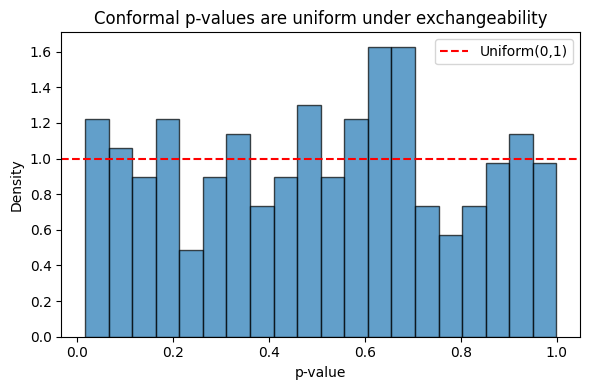

In [12]:

cp_pv = ConformalRidgeRegressor(a=1.0, rnd_state=0)
cp_pv.learn_initial_training_set(X[:50], y[:50])

p_values = []
for i in range(50, 300):
    p_values.append(cp_pv.compute_p_value(X[i], y[i]))
    cp_pv.learn_one(X[i], y[i])

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(p_values, bins=20, density=True, alpha=0.7, edgecolor="black")
ax.axhline(1.0, color="red", ls="--", label="Uniform(0,1)")
ax.set_xlabel("p-value")
ax.set_ylabel("Density")
ax.set_title("Conformal p-values are uniform under exchangeability")
ax.legend()
plt.tight_layout()
plt.show()



**Regressors recap**

| class | when to use |
|-------|-------------|
| `ConformalRidgeRegressor` | baseline; linear, low/medium dimension |
| `KernelConformalRidgeRegressor` | nonlinear targets; any of the kernels above |
| `ConformalLassoRegressor` | high dimension + sparsity; exact L1 conformalization |
| `ConformalNearestNeighboursRegressor` | model-free, high-dim, robust baseline |

**Metrics recap** — `ErrorRate` (coverage), `IntervalWidth` (sharpness),
`WinklerScore` (proper interval scoring rule). All update with
`metric.update(y=..., Gamma=pred_set)` or, more conveniently, via the
evaluation loop.

**Next**: §2 — prediction *sets* for classification.



---

## 2. What about classification? (Prediction sets)

> *I don't want a probability — I want a **set of candidate classes** that I can
> trust to contain the truth. And I want to know when the object is just
> weird.*

For classification, conformal prediction returns a **prediction set**
$\Gamma \subseteq \{labels\}$:

* **singleton** `{2}` → confident
* **multi** `{0, 2}` → genuinely uncertain between those classes
* **empty** `{}` → everything looks anomalous (happens at most $\varepsilon$ of
  the time)

### 2.1 k-NN classifier on the Wine dataset

`ConformalNearestNeighboursClassifier` scores each candidate label by the ratio
of distance to its own nearest neighbours vs. to other classes' neighbours.


In [13]:

from online_cp import ConformalNearestNeighboursClassifier, SetSize, ObservedFuzziness
from sklearn.datasets import load_wine

wine = load_wine()
perm_w = rng.permutation(len(wine.target))
X_w, y_w = wine.data[perm_w], wine.target[perm_w]
labels = np.unique(y_w)

knn = ConformalNearestNeighboursClassifier(k=5, label_space=labels, rnd_state=42)
knn.learn_initial_training_set(X_w[:30], y_w[:30])

metric_knn = ErrorRate() + SetSize() + ObservedFuzziness()
progressive_val(knn, X_w[30:], y_w[30:], epsilon=0.1, metric=metric_knn)

sizes = np.array(metric_knn["SetSize"].values)
print(f"Error rate            : {metric_knn['ErrorRate'].get():.3f}  (target <= 0.1)")
print(f"Average set size      : {metric_knn['SetSize'].get():.2f}")
print(f"Singletons (confident): {np.mean(sizes == 1):.0%}")
print(f"Empty sets (anomaly)  : {np.mean(sizes == 0):.0%}")


Error rate            : 0.047  (target <= 0.1)
Average set size      : 1.56
Singletons (confident): 49%
Empty sets (anomaly)  : 0%



### 2.2 SVM classifier — sharper sets, more compute

`ConformalSupportVectorMachine` uses a kernel SVM (one-vs-rest) as the
nonconformity measure. Because the SVM scores each class with a smooth kernel,
its margins are more *confident* than raw k-NN, so — **on a properly scaled
input** — the conformal sets are usually **smaller** (often singletons). Two
nonconformity choices are available via `nonconformity` (`"margin"` default
and the signed-margin variant). Let's compare both and watch the set size
evolve.

> **A practical catch:** an RBF kernel is scale-sensitive. The Wine features
> range from ~0.1 to ~1680, so we *standardise* first and pick `sigma` to match
> the (now unit) feature scale. With a poorly matched `sigma` the SVM looks
> worse than k-NN; with a good one it is noticeably sharper.


In [14]:

from online_cp import ConformalSupportVectorMachine
from sklearn.preprocessing import StandardScaler

# Standardise first: RBF is scale-sensitive and the Wine features span ~0.1..1680.
X_w_s = StandardScaler().fit_transform(X_w)

svm = ConformalSupportVectorMachine(kernel="rbf", sigma=2.0, C=1.0, label_space=labels, rnd_state=42)
svm.learn_initial_training_set(X_w_s[:30], y_w[:30])

metric_svm = ErrorRate() + SetSize()
progressive_val(svm, X_w_s[30:], y_w[30:], epsilon=0.1, metric=metric_svm)

print(f"KNN — error: {metric_knn['ErrorRate'].get():.3f}, avg set size: {metric_knn['SetSize'].get():.2f}  (raw features)")
print(f"SVM — error: {metric_svm['ErrorRate'].get():.3f}, avg set size: {metric_svm['SetSize'].get():.2f}  (standardised features)")


KNN — error: 0.047, avg set size: 1.56  (raw features)
SVM — error: 0.088, avg set size: 0.92  (standardised features)


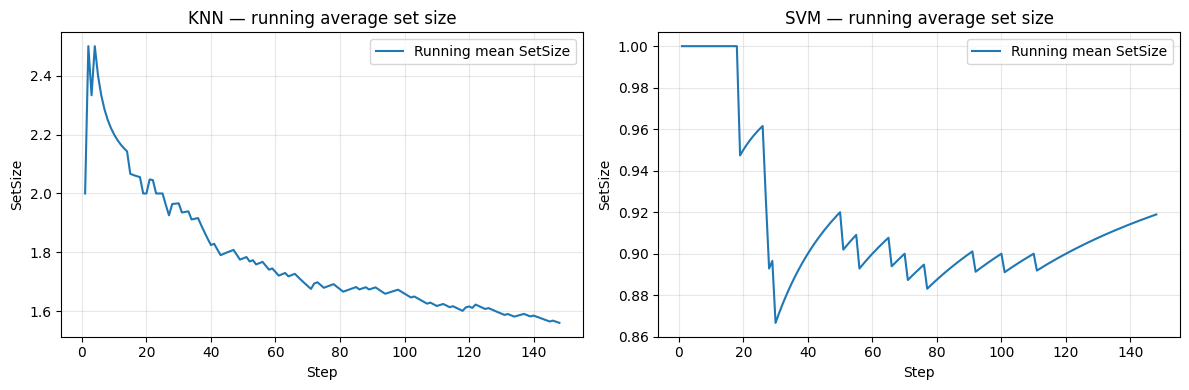

In [15]:

from online_cp.plotting import plot_set_sizes

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_set_sizes(metric_knn["SetSize"], ax=axes[0]); axes[0].set_title("KNN — running average set size")
plot_set_sizes(metric_svm["SetSize"], ax=axes[1]); axes[1].set_title("SVM — running average set size")
plt.tight_layout()
plt.show()



#### Classification-specific metrics

* `SetSize` — average number of labels in the set (efficiency).
* `ObservedExcess` — number of *false* labels inside the set (precision view).
* `ObservedFuzziness` — sum of p-values of the false labels (calibration view).
* `ErrorRate` — miscoverage, the core guarantee ($\le \varepsilon$).



### 2.3 Multi-level prediction sets

Same "zoom" idea as §0.4, now on classes — one call returns nested sets at
every confidence level.


In [16]:

knn2 = ConformalNearestNeighboursClassifier(k=5, label_space=labels, rnd_state=42)
knn2.learn_initial_training_set(X_w[:80], y_w[:80])

Gamma = knn2.predict(X_w[80], epsilon=[0.01, 0.05, 0.1, 0.2, 0.5])
print(f"True label: {y_w[80]}\n")
for eps, pred_set in Gamma:
    cover = "covered" if y_w[80] in pred_set else "missed"
    print(f"  epsilon={eps:.2f}: {list(pred_set.elements)}  (size {len(pred_set)})  -> {cover}")
print("\nLarger epsilon = larger (looser) set, so it keeps covering the true\n")
print("label; the ultra-strict epsilon=0.5 set is a single point prediction\n")
print("which happens to land on the wrong class here.")


True label: 0

  epsilon=0.01: [np.int64(1), np.int64(2)]  (size 2)  -> missed
  epsilon=0.05: [np.int64(1), np.int64(2)]  (size 2)  -> missed
  epsilon=0.10: [np.int64(1), np.int64(2)]  (size 2)  -> missed
  epsilon=0.20: [np.int64(1), np.int64(2)]  (size 2)  -> missed
  epsilon=0.50: []  (size 0)  -> missed

Larger epsilon = larger (looser) set, so it keeps covering the true

label; the ultra-strict epsilon=0.5 set is a single point prediction

which happens to land on the wrong class here.



### 2.4 Bring your own distance metric

The NCM only needs a distance. You can pass any `'metric'` string recognised by
`scipy.spatial.distance.cdist`, or supply your **own** distance function with
`distance_func`. A registered callable can even be serialised (see §8).


In [17]:

import numpy as np
from scipy.spatial.distance import cdist, pdist, squareform
from online_cp import register_callable

@register_callable("mahalanobis_l2")
def my_mahalanobis(X, y=None):
    'A simple scaled Euclidean distance (stand-in for a true Mahalanobis).'
    if y is None:
        return squareform(pdist(X, metric="euclidean"))
    y = np.atleast_2d(y)                    # handle a single 1-D test point
    return cdist(X, y, metric="euclidean") * 0.5

knn_custom = ConformalNearestNeighboursClassifier(k=5, label_space=labels, distance_func=my_mahalanobis, rnd_state=1)
knn_custom.learn_initial_training_set(X_w[:30], y_w[:30])
m_c = ErrorRate() + SetSize()
progressive_val(knn_custom, X_w[30:], y_w[30:], epsilon=0.1, metric=m_c)
print(f"Custom-distance kNN  error={m_c['ErrorRate'].get():.3f}  set size={m_c['SetSize'].get():.2f}")


Custom-distance kNN  error=0.061  set size=1.53



**Classifiers recap**

| class | note |
|-------|------|
| `ConformalNearestNeighboursClassifier` | ratio-of-distances NCM; fast, model-free |
| `ConformalSupportVectorMachine` | kernel SVM; sharper sets, more compute |

Both accept `label_space`, a `distance`/`distance_func`, and multi-level `epsilon`.

**Next**: §3 — if you specifically need a *calibrated probability*, use a
Venn predictor.



---

## 3. Do I need calibrated probabilities? (Venn-Abers predictors)

> *Conformal predictors give me **sets**, but my dashboard needs a number —
> $P(y=1)$. Can I get a **calibrated** probability without splitting my data
> into train/calibration/test?* 

Yes — with the **Venn-Abers predictor** (ALRW2 §6.4). Instead of a set it
outputs a **multiprobability** $P = \{P^v : v \in Y\}$, one distribution over
labels for each hypothesis about the test label. For binary labels this is a
pair $(p^0, p^1)$:

* $p^0$ — calibrated $P(y=1)$ assuming the true label is $0$
* $p^1$ — calibrated $P(y=1)$ assuming the true label is $1$

The **pair is the prediction** (not a point estimate). For decision-making you
merge it with `log_loss_point(p0, p1)` (minimises log loss) or
`brier_point(p0, p1)` (minimises Brier loss). This is the **full/transductive**
variant — the scorer is retrained on the augmented bag for each hypothesis and
isotonically calibrated (PAVA), so no data split is required.


In [18]:

from online_cp import VennAbersPredictor, log_loss_point, brier_point
from online_cp.plotting import (
    plot_reliability_diagram_venn, plot_sharpness, plot_calibration_conditional,
)
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

# Binary, real data: Breast Cancer (malignant=1 / benign=0).
bc = load_breast_cancer()
perm_bc = rng.permutation(len(bc.target))
X_bc, y_bc = bc.data[perm_bc], bc.target[perm_bc]
X_bc_s = StandardScaler().fit_transform(X_bc)

# We use a ridge scorer: the smoother scores give a nicely spread reliability
# diagram (the kNN scorer is very confident on this easy task and would pile
# its probabilities up in the corners).
vap = VennAbersPredictor(scorer="ridge", a=1.0)
vap.learn_initial_training_set(X_bc_s[:50], y_bc[:50])

# Stream predictions, keeping the VennPrediction objects and true labels.
preds, labels_test = [], []
for i in range(50, 400):
    preds.append(vap.predict(X_bc_s[i]))
    labels_test.append(y_bc[i])
    vap.learn_one(X_bc_s[i], y_bc[i])

labels_test = np.array(labels_test)
p0 = np.array([p.p0 for p in preds]); p1 = np.array([p.p1 for p in preds])
merged = np.array([log_loss_point(a, b) for a, b in zip(p0, p1)])
width = p1 - p0

print(f"Mean merged P(y=1) for true positives : {merged[labels_test == 1].mean():.3f}")
print(f"Mean merged P(y=1) for true negatives : {merged[labels_test == 0].mean():.3f}")
print(f"Accuracy @ threshold 0.5             : {np.mean((merged > 0.5) == labels_test):.3f}")
print(f"Mean multiprobability width (p1-p0)  : {width.mean():.3f}")


Mean merged P(y=1) for true positives : 0.870
Mean merged P(y=1) for true negatives : 0.254
Accuracy @ threshold 0.5             : 0.909
Mean multiprobability width (p1-p0)  : 0.177


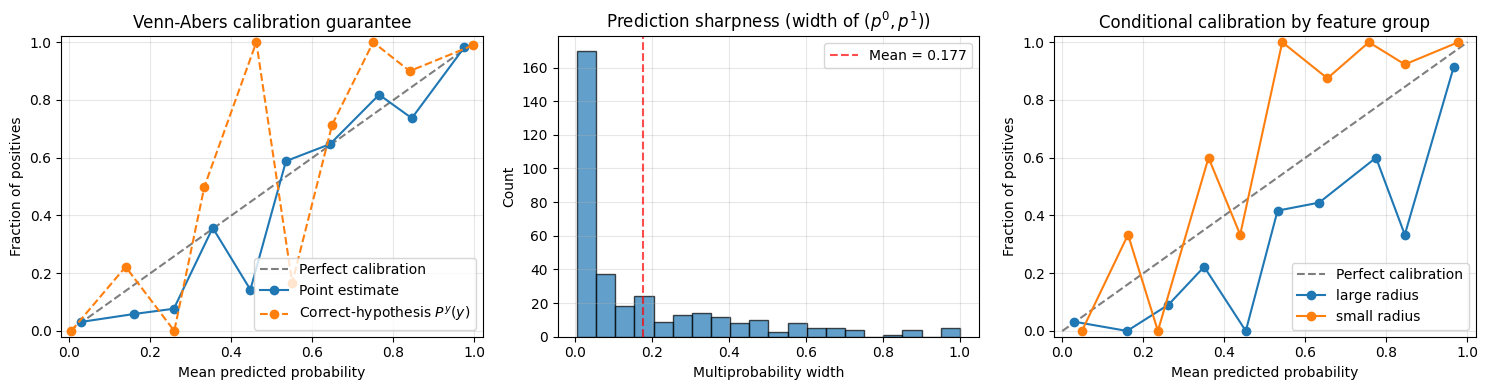

In [19]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1) The Venn calibration guarantee, visualised.
plot_reliability_diagram_venn(preds, labels_test, ax=axes[0])
axes[0].set_title("Venn-Abers calibration guarantee")

# 2) Sharpness: distribution of multiprobability width (p1 - p0).
plot_sharpness(preds, ax=axes[1])
axes[1].set_title("Prediction sharpness (width of $(p^0, p^1)$)")

# 3) Conditional calibration by feature group (large vs small mean radius).
from online_cp import CalibrationError
median_radius = np.median(X_bc_s[:, 0])
ce_large, ce_small = CalibrationError(), CalibrationError()
# re-stream to populate per-group ECE (fresh predictor, same data)
vap_c = VennAbersPredictor(scorer="ridge", a=1.0)
vap_c.learn_initial_training_set(X_bc_s[:50], y_bc[:50])
for i in range(50, 400):
    pr = vap_c.predict(X_bc_s[i])
    (ce_large if X_bc_s[i, 0] > median_radius else ce_small).update(y=y_bc[i], venn=pr)
    vap_c.learn_one(X_bc_s[i], y_bc[i])
plot_calibration_conditional({"large radius": ce_large, "small radius": ce_small}, ax=axes[2])
axes[2].set_title("Conditional calibration by feature group")

plt.tight_layout()
plt.show()



Three facets of the Venn guarantee:

* **Reliability diagram** (`plot_reliability_diagram_venn`): the correct-
  hypothesis probability $P^y(y)$ is theoretically calibrated by Venn validity
  (ALRW2 Thm 6.4); the point estimate is calibrated empirically.
* **Sharpness** (`plot_sharpness`): narrow pairs = informative, wide pairs =
  genuine uncertainty.
* **Conditional calibration** (`plot_calibration_conditional`): per-group ECE —
  confirms calibration holds across subpopulations, not just marginally.

### 3.1 The other Venn predictors

`VennAbersPredictor` supports three scorers, and two further Venn classes give
you different *taxonomies* (the grouping that makes the empirical frequencies
valid):


In [20]:

# 1) Ridge-scored Venn-Abers (smooth scores -> informative (p0, p1) pair)
vap_ridge = VennAbersPredictor(scorer="ridge", a=1.0)
# 2) Nearest-neighbour *voting* Venn (k+1 categories = #positive among k NN)
from online_cp import NearestNeighboursVennPredictor
nn_venn = NearestNeighboursVennPredictor(k=5, metric="euclidean")

for name, mdl in {"VennAbers(ridge)": vap_ridge,
                  "NN-Venn(k=5)": nn_venn}.items():
    mdl.learn_initial_training_set(X_bc_s[:50], y_bc[:50])
    pr = mdl.predict(X_bc_s[50])
    print(f"{name:16s}  (p0, p1) = ({pr.p0:.3f}, {pr.p1:.3f})   merged={(pr.p0+pr.p1)/2:.3f}")

# Note: the Mondrian-tree Venn (`MondrianVennPredictor`) and the SVM scorer
# also work, but on this easy task they are so confident that they almost
# always return the degenerate (0.0, 1.0) pair -- the pair is only wide when
# the underlying scorer is itself uncertain about the example.


VennAbers(ridge)  (p0, p1) = (0.833, 1.000)   merged=0.917
NN-Venn(k=5)      (p0, p1) = (0.960, 1.000)   merged=0.980



### 3.2 Multiclass Venn

For $|Y|>2$ the output is a `MulticlassVennPrediction` carrying the full
$|Y| \times |Y|$ matrix $P^{label\_i}(label\_j)$; `.point` gives a merged
point estimate per class.


In [21]:

from online_cp import NearestNeighboursVennPredictor, MulticlassVennPrediction

# Use the Wine 3-class data from §2.
mc_venn = NearestNeighboursVennPredictor(k=3, label_space=labels)
mc_venn.learn_initial_training_set(X_w[:60], y_w[:60])
pr = mc_venn.predict(X_w[60])
print(type(pr).__name__, "| matrix shape:", pr.probs.shape)
print("probs matrix (rows = hypothesis, cols = predicted class):")
print(np.round(pr.probs, 3))
print("merged point estimate:", np.round(pr.point, 3), "  true label:", y_w[60])


VennPrediction | matrix shape: (3, 3)
probs matrix (rows = hypothesis, cols = predicted class):
[[0.45 0.45 0.1 ]
 [0.3  0.5  0.2 ]
 [0.3  0.4  0.3 ]]
merged point estimate: [0.35 0.45 0.2 ]   true label: 0



**Venn recap**

| class | taxonomy / scorer |
|-------|-------------------|
| `VennAbersPredictor` | scorer = `ridge` / `knn` / `svm` (ALRW2 §6.4) |
| `NearestNeighboursVennPredictor` | k-NN voting taxonomy |
| `MondrianVennPredictor` | Mondrian-tree leaf taxonomy |

* Merge binary pairs with `log_loss_point` / `brier_point`.
* Metrics: `BrierScore`, `LogLoss`, `Width`, `CalibrationError` (all update
  with `update(y=..., venn=...)`).

**Next**: §4 — guaranteeing coverage *within* subgroups (Mondrian CP).



---

## 4. Is it fair to every subgroup? (Mondrian conformal prediction)

> *My intervals cover 90% **on average** — but are some groups (e.g. high-risk
> patients, rare species) systematically under-covered?*

Standard conformal prediction guarantees **marginal** coverage. **Mondrian**
conformal prediction guarantees coverage *within each group*:

$$\mathbb{P}\bigl(y \in \Gamma^{\varepsilon} \mid \kappa(x,y)=k\bigr) \ge 1-\varepsilon \quad \forall k .$$

The trick: train **one pooled model** on all data, but calibrate the interval
only against same-category training examples. Below we use a *regressor* — it
makes the under-coverage effect the cleanest to see — but the same class
(`MondrianConformalClassifier`) works identically for classification.


In [22]:

from online_cp import MondrianConformalRegressor

# Two subgroups with very different LOCAL noise:
#   * "low"  : y = 5*x + small noise  -> Ridge easily predicts it
#   * "high" : y = 5*x + large noise  -> Ridge's own error rate is much higher
#
# A *single* (marginal) model pools all calibration residuals. The low-noise
# group's tiny errors drag the pooled quantile down, so the intervals are too
# tight for the high-noise group and miscoverage there blows up. Mondrian CP
# calibrates *separately per group*, so each group gets its own (correct)
# residual quantile.

rng_m = np.random.default_rng(1)
n = 900
x = np.linspace(0, 1, n).reshape(-1, 1) + rng_m.normal(0, 0.1, (n, 1))
g = np.zeros(n); g[450:] = 1          # first 450 pts = "low", rest = "high"
noise = rng_m.normal(0, 1.0, n)
y_m = x[:, 0] * 5 + np.where(g == 0, noise * 0.3, noise * 1.4)
X_m = np.hstack([x, g.reshape(-1, 1)])
perm = rng_m.permutation(n); X_m, y_m = X_m[perm], y_m[perm]

category_fn = lambda x: "high" if x[1] > 0.5 else "low"
warm = 150

std_reg = ConformalRidgeRegressor(a=1.0)
std_reg.learn_initial_training_set(X_m[:warm], y_m[:warm])

mond_reg = MondrianConformalRegressor(
    base_model=ConformalRidgeRegressor(a=1.0),
    category_fn=category_fn,
)
mond_reg.learn_initial_training_set(X_m[:warm], y_m[:warm])

errors_std, errors_mond = {"low": [], "high": []}, {"low": [], "high": []}
for i in range(warm, len(X_m)):
    cat = category_fn(X_m[i])
    iv_std = std_reg.predict(X_m[i], epsilon=0.1)
    errors_std[cat].append(y_m[i] < iv_std.lower or y_m[i] > iv_std.upper)
    std_reg.learn_one(X_m[i], y_m[i])
    iv_mon = mond_reg.predict(X_m[i], epsilon=0.1)
    errors_mond[cat].append(y_m[i] < iv_mon.lower or y_m[i] > iv_mon.upper)
    mond_reg.learn_one(X_m[i], y_m[i])

print("Per-group miscoverage (target <= 0.10 for every group):")
print(f"{'Method':<12} {'Low noise':>10} {'High noise':>10}")
print(f"{'Standard':<12} {np.mean(errors_std['low']):>10.3f} {np.mean(errors_std['high']):>10.3f}")
print(f"{'Mondrian':<12} {np.mean(errors_mond['low']):>10.3f} {np.mean(errors_mond['high']):>10.3f}")


Per-group miscoverage (target <= 0.10 for every group):
Method        Low noise High noise
Standard          0.000      0.205
Mondrian          0.079      0.108


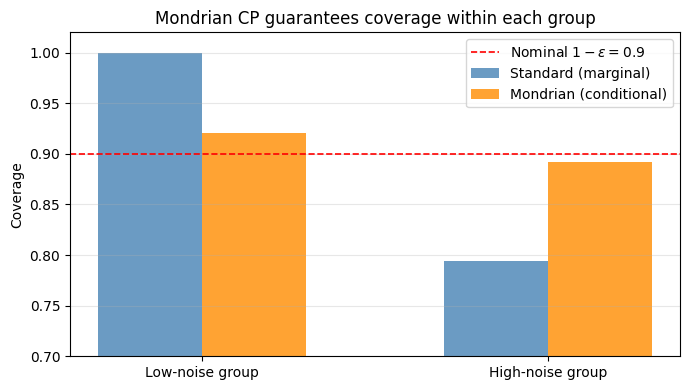

In [23]:

groups = ["low", "high"]
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(groups)); w = 0.3
cov_std  = [1 - np.mean(errors_std[g])  for g in groups]
cov_mond = [1 - np.mean(errors_mond[g]) for g in groups]
ax.bar(x - w/2, cov_std,  w, label="Standard (marginal)",  color="steelblue", alpha=0.8)
ax.bar(x + w/2, cov_mond, w, label="Mondrian (conditional)", color="darkorange", alpha=0.8)
ax.axhline(0.9, color="red", ls="--", lw=1.2, label="Nominal $1-\\varepsilon = 0.9$")
ax.set_xticks(x); ax.set_xticklabels(["Low-noise group", "High-noise group"])
ax.set_ylabel("Coverage"); ax.set_ylim(0.7, 1.02)
ax.set_title("Mondrian CP guarantees coverage within each group")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### 4.1 Label-conditional Mondrian (the imbalance remedy)

The most common special case is **label-conditional** CP — group by the label
itself. Use the convenience `category_fn="label"`; it guarantees per-class
coverage, the standard remedy for class imbalance.


In [24]:

from online_cp import MondrianConformalClassifier

# Its own 3-class data: label-conditional CP is the standard remedy for imbalance.
N = 400
X_lbl = rng.normal(size=(N, 3))
y_lbl = np.digitize(X_lbl.sum(1), bins=[-1, 1])   # 3 classes

mon_label = MondrianConformalClassifier(
    base_model=ConformalNearestNeighboursClassifier(k=5),
    category_fn="label",
)
mon_label.learn_initial_training_set(X_lbl[:40], y_lbl[:40])

per = {c: [] for c in range(3)}
for i in range(40, N):
    G = mon_label.predict(X_lbl[i], epsilon=0.1)
    per[y_lbl[i]].append(y_lbl[i] not in G)
    mon_label.learn_one(X_lbl[i], y_lbl[i])

print("Per-class miscoverage (label-conditional, target <= 0.1 each):")
for c in range(3):
    print(f"  class {c}: miscoverage = {np.mean(per[c]):.3f}")


Per-class miscoverage (label-conditional, target <= 0.1 each):
  class 0: miscoverage = 0.125
  class 1: miscoverage = 0.108
  class 2: miscoverage = 0.064



### 4.3 Mondrian **trees** and **forests** — a *different* mechanism

> **Not the same as Mondrian CP above.** The Mondrian classifier/regressor in
> §4.1–4.2 is a *calibration wrapper*: any base model plus per-group error
> quantiles. A Mondrian **tree** (or **forest**) is instead a *predictor in its
> own right* — it learns a hierarchy of random feature splits that partitions
> the space into leaves, and calibrates inside each leaf. The tree *is* the
> model; nothing is wrapped. The package ships it with rich **inspection**
> utilities (`.summary`, `.to_dataframe()`, `.draw()`, `.draw_partition()`).


tree.summary (a dict): {'n_points': 80, 'n_classes': 3, 'lifetime': 2.0}

Tree structure (first 5 nodes of to_dataframe()):
   node_id  is_leaf  depth  n_points
0        0    False      0         0
1        1     True      1         3
2        2    False      1         0
3        3    False      2         0
4        4     True      3         1


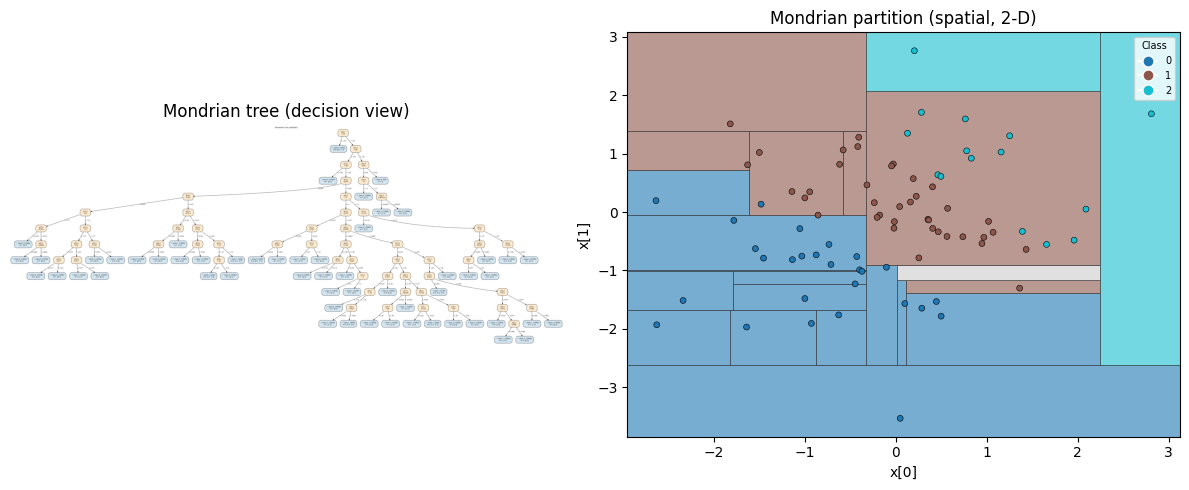

In [25]:

from online_cp import ConformalMondrianTreeClassifier, ConformalMondrianForestClassifier

# Its own small 3-class dataset (the Mondrian tree *is* the model here).
X_t = rng.normal(size=(240, 3))
y_t = np.digitize(X_t.sum(1), bins=[-1, 1])   # 3 classes

mt = ConformalMondrianTreeClassifier(lifetime=2.0, label_space=np.array([0,1,2]), rnd_state=1)
mt.learn_initial_training_set(X_t[:80], y_t[:80])
mt.predict(X_t[80], epsilon=0.1)             # builds the tree (needed for inspection)

print("tree.summary (a dict):", {k: mt.summary[k] for k in ['n_points','n_classes','lifetime']})
df = mt.to_dataframe()
print("\nTree structure (first 5 nodes of to_dataframe()):")
print(df[['node_id','is_leaf','depth','n_points']].head())

# Draw the decision tree and the spatial partition (2-D data required for draw_partition).
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
mt.draw(ax=axes[0]); axes[0].set_title("Mondrian tree (decision view)")

# draw_partition needs exactly 2 features — use a dedicated 2-D slice:
X2 = rng.normal(size=(300, 2))
y2 = np.digitize(X2.sum(1), bins=[-1, 1])
mt2 = ConformalMondrianTreeClassifier(lifetime=2.0, label_space=np.array([0,1,2]), rnd_state=1)
mt2.learn_initial_training_set(X2[:80], y2[:80]); mt2.predict(X2[80], epsilon=0.1)
mt2.draw_partition(ax=axes[1]); axes[1].set_title("Mondrian partition (spatial, 2-D)")
plt.tight_layout()
plt.show()


In [26]:

# Forest (ensemble of trees) + the Mondrian *regressor* tree.
from online_cp import ConformalMondrianForestClassifier, ConformalMondrianTreeRegressor

mf = ConformalMondrianForestClassifier(n_trees=5, lifetime=0.5, label_space=np.array([0,1,2]), rnd_state=1)
mf.learn_initial_training_set(X_t[:80], y_t[:80])
print("Mondrian forest prediction set:", list(mf.predict(X_t[80], epsilon=0.1).elements))

Xr = rng.normal(size=(200, 3)); yr = Xr.sum(1) + rng.normal(0, 0.2, 200)
mtr = ConformalMondrianTreeRegressor(lifetime=0.5, rnd_state=1)
mtr.learn_initial_training_set(Xr[:80], yr[:80])
iv = mtr.predict(Xr[80], epsilon=0.1)
print(f"Mondrian tree regressor interval: width={iv.width():.3f}")


Mondrian forest prediction set: [np.int64(1), np.int64(2)]
Mondrian tree regressor interval: width=4.766



**Mondrian recap**

* `MondrianConformalRegressor` / `MondrianConformalClassifier` — wrap any base
  model; `category_fn` is a callable `(x[, y]) -> hashable` or `"label"`.
* `ConformalMondrianTree{Regressor,Classifier}` & `...Forest{Regressor,Classifier}`
  — the partition *is* the model; use `.summary` (property), `.to_dataframe()`,
  `.draw()`, `.draw_partition()` (2-D only).

**Next**: §5 — the *full* predictive distribution (Conformal Predictive Systems).



---

## 5. What does the full predictive distribution look like? (CPS)

> *An interval is just one slice of a CDF. Can I see the **entire** predictive
distribution — and pull out an interval at *any* level I want?*

A **Conformal Predictive System (CPS)** produces a full conformal predictive
distribution (CPD): a function $Q(y)$ you can evaluate, plot, and invert to
get prediction sets at arbitrary $\varepsilon$.


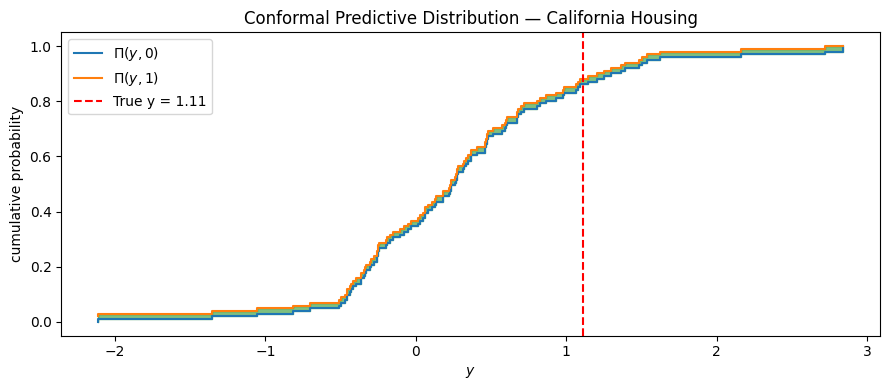

In [27]:

from online_cp import RidgePredictionMachine

# Reuse the California Housing data (permuted X, y from §0).
cps = RidgePredictionMachine(a=1.0)
cps.learn_initial_training_set(X[:100], y[:100])
cpd = cps.predict(X[100])

fig = cpd.plot()
fig.set_size_inches(9, 4)
ax = fig.axes[0]
ax.axvline(y[100], color="red", ls="--", lw=1.5, label=f"True y = {y[100]:.2f}")
ax.legend(); ax.set_title("Conformal Predictive Distribution — California Housing")
fig.tight_layout()
fig


In [28]:

# The CPD exposes a small calculus:
tau = rng.uniform()
print(f"CPD median            : {cpd.median():.3f}")
print(f"CPD 90% quantile      : {cpd.quantile(0.9, tau=tau):.3f}")
print(f"CPD width @ eps=0.1   : {cpd.predict_set(tau, epsilon=0.1).width():.3f}")

# Intervals at several levels from the SAME cpd:
print("\nIntervals from one CPD:")
for eps in [0.01, 0.05, 0.1, 0.2]:
    iv = cpd.predict_set(tau, epsilon=eps)
    hit = "\u2713" if y[100] in iv else "\u2717"
    lo, hi = iv.to_single_interval()
    print(f"  epsilon={eps:.2f}: [{lo:.2f}, {hi:.2f}]  width={iv.width():.2f}  {hit}")

# The CPD evaluated at the true y is itself a conformal p-value.
print(f"\nCPD(y_true, tau) = {cpd(y[100], tau):.3f}  (a valid p-value)")


CPD median            : 0.237
CPD 90% quantile      : 1.298
CPD width @ eps=0.1   : 2.237

Intervals from one CPD:
  epsilon=0.01: [-2.11, inf]  width=inf  ✓
  epsilon=0.05: [-1.05, 2.72]  width=3.77  ✓
  epsilon=0.10: [-0.70, 1.54]  width=2.24  ✓
  epsilon=0.20: [-0.46, 1.30]  width=1.75  ✓

CPD(y_true, tau) = 0.864  (a valid p-value)



### 5.1 PIT calibration & CRPS metrics

Under a well-calibrated CPD, the **Probability Integral Transform**
$p_t = Q(y_t; \tau)$ is uniform. We check that with a PIT histogram, and score
predictive accuracy with the (Truncated / Conformal) CRPS.


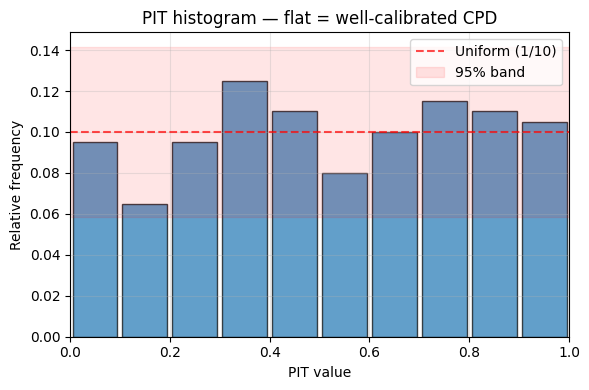

TruncatedCRPS = 0.3769  (proper, truncated to data support)
ConformalCRPS = 1.1875  (uses the CPD's own CDF)


In [29]:

from online_cp import TruncatedCRPS, ConformalCRPS
from online_cp.plotting import plot_pit_histogram

cps_pit = RidgePredictionMachine(a=1.0)
cps_pit.learn_initial_training_set(X[:100], y[:100])
rng_tau = np.random.default_rng(7)
pit_values = []
trcrps, ccrps = TruncatedCRPS(), ConformalCRPS()

for i in range(100, 300):
    tau = rng_tau.uniform()
    cpd = cps_pit.predict(X[i])
    pit_values.append(cpd(y[i], tau))
    trcrps.update(y=y[i], cpd=cpd)
    ccrps.update(y=y[i], cpd=cpd)
    cps_pit.learn_one(X[i], y[i])

fig, ax = plt.subplots(figsize=(6, 4))
plot_pit_histogram(pit_values, ax=ax)
ax.set_title("PIT histogram — flat = well-calibrated CPD")
plt.tight_layout()
plt.show()

print(f"TruncatedCRPS = {trcrps.get():.4f}  (proper, truncated to data support)")
print(f"ConformalCRPS = {ccrps.get():.4f}  (uses the CPD's own CDF)")



### 5.2 The other CPS variants

| class | basis |
|-------|-------|
| `RidgePredictionMachine` | ridge studentised residuals (linear) |
| `KernelRidgePredictionMachine` | kernel ridge, any kernel |
| `NearestNeighboursPredictionMachine` | nonparametric k-NN |
| `DempsterHillConformalPredictiveSystem` | label-only (no covariates) baseline |
| `MondrianTreePredictionMachine` | Mondrian tree, leaf-local signed residuals |


In [30]:

from online_cp import (
    KernelRidgePredictionMachine, NearestNeighboursPredictionMachine,
    DempsterHillConformalPredictiveSystem, MondrianTreePredictionMachine, GaussianKernel,
)

cps_models = {
    "KernelRidge": KernelRidgePredictionMachine(kernel=GaussianKernel(sigma=1.5), a=0.5),
    "k-NN (k=5)"  : NearestNeighboursPredictionMachine(k=15),
    "MondrianTree": MondrianTreePredictionMachine(lifetime=0.5, rnd_state=1),
}
for name, mdl in cps_models.items():
    mdl.learn_initial_training_set(X_nl[:60], y_nl[:60])
    cpd = mdl.predict(X_nl[60])
    print(f"{name:13s} median={cpd.median():8.3f}  width@0.1={cpd.predict_set(0.5, epsilon=0.1).width():7.3f}")

# Label-only baseline (ignores x entirely) — needs only y.
dh = DempsterHillConformalPredictiveSystem(epsilon=0.1)
dh.learn_initial_training_set(y_nl[:60])
cpd_dh = dh.predict(None)
print(f"{'Dempster-Hill':13s} median={cpd_dh.median():8.3f}  width@0.1={cpd_dh.predict_set(0.5, epsilon=0.1).width():7.3f}  (no covariates)")


KernelRidge   median=   3.602  width@0.1=  2.139
k-NN (k=5)    median=   2.647  width@0.1=  4.622
MondrianTree  median=   4.252  width@0.1=  3.129
Dempster-Hill median=   1.182  width@0.1=  5.066  (no covariates)



**CPS recap** — every CPS returns a CPD supporting `.plot()`, `.median()`,
`.quantile(q)`, `.width()`, `.predict_set(tau, epsilon=...)`, and evaluation
`cpd(y, tau)` (a p-value). Metrics `CRPS`, `TruncatedCRPS`, `ConformalCRPS`
score them.

**Next**: §6 — what if the data *changes* over time? Detect it online.



---

## 6. What if the data distribution changes? (Conformal test martingales)

> *Conformal prediction **assumes** exchangeability. What if my sensor drifts,
or a market regime changes — can I **detect that online**, with a
> distribution-free test?* 

Conformal **test martingales** turn the stream of p-values into a wealth
process $M_n$. Under exchangeability $\mathbb{E}[M_n] \le 1$; when the
distribution shifts, p-values stop being uniform and $M_n$ grows. By
**Ville's inequality**, $\mathbb{P}(\exists n: M_n \ge c) \le 1/c$ — so a
growing martingale is statistically significant evidence of shift.

### 6.1 Exchangeable data — the martingale stays small


In [31]:

from online_cp import SimpleJumper, SimpleMixtureMartingale, CompositeJumper
from online_cp.plotting import plot_martingale, plot_detector

# Exchangeable (permuted) data.
cp_exch = ConformalRidgeRegressor(a=1.0, rnd_state=0)
cp_exch.learn_initial_training_set(X[:50], y[:50])

mart_exch = SimpleJumper()
for i in range(50, 290):
    mart_exch.update(cp_exch.compute_p_value(X[i], y[i]))
    cp_exch.learn_one(X[i], y[i])

print(f"Final martingale value: {mart_exch.M:.2f}  (stays small -> looks exchangeable)")


Final martingale value: 0.18  (stays small -> looks exchangeable)



### 6.2 Distribution shift — the martingale explodes


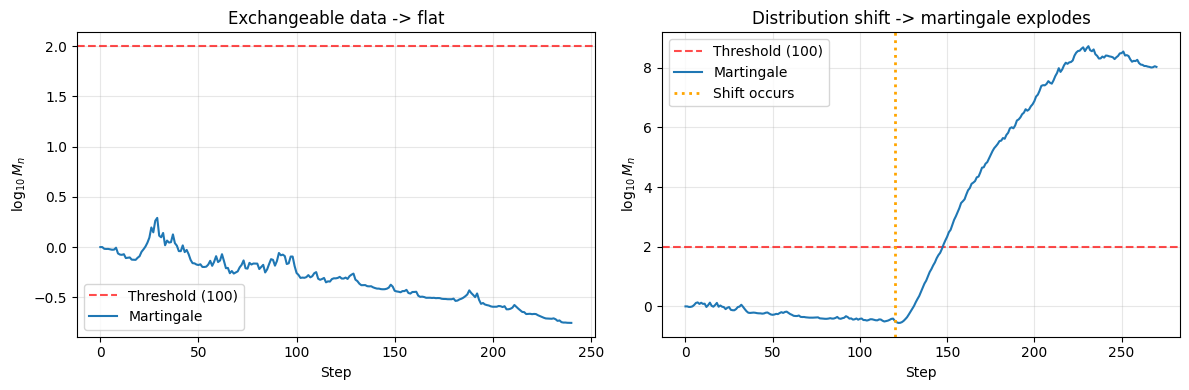


Max log-martingale after shift: 20.1


In [32]:

# Synthetic data with a mean shift at t=150.
N_shift = 300
rng_s = np.random.default_rng(456)
X_s = rng_s.normal(size=(N_shift, 3))
y_s = np.empty(N_shift)
y_s[:150] = X_s[:150] @ [1, -1, 0.5] + rng_s.normal(0, 0.3, 150)
y_s[150:] = X_s[150:] @ [1, -1, 0.5] + 3.0 + rng_s.normal(0, 0.3, 150)  # shift!

cp_s = ConformalRidgeRegressor(a=1.0, rnd_state=0)
cp_s.learn_initial_training_set(X_s[:30], y_s[:30])

mart_shift = SimpleJumper()
for i in range(30, N_shift):
    mart_shift.update(cp_s.compute_p_value(X_s[i], y_s[i]))
    cp_s.learn_one(X_s[i], y_s[i])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_martingale(mart_exch, ax=axes[0]); axes[0].set_title("Exchangeable data -> flat")
plot_martingale(mart_shift, ax=axes[1])
axes[1].axvline(150 - 30, color="orange", ls=":", lw=2, label="Shift occurs")
axes[1].legend(); axes[1].set_title("Distribution shift -> martingale explodes")
plt.tight_layout()
plt.show()

print(f"\nMax log-martingale after shift: {max(mart_shift.log_martingale_values):.1f}")



### 6.3 Turn it into a test: the detection wrappers

* **`VilleWrapper`** — reject when the running max exceeds a threshold $c$.
  $c=20$ → 5% test, $c=100$ → 1%.
* **`CUSUMWrapper`** — tracks $\max_k M_n/M_k$; resets after each alarm, so it
  detects *multiple* change-points.
* **`ShiryaevRobertsWrapper`** — tracks the average ratio; often a bit faster.

All wrap *any* base martingale.


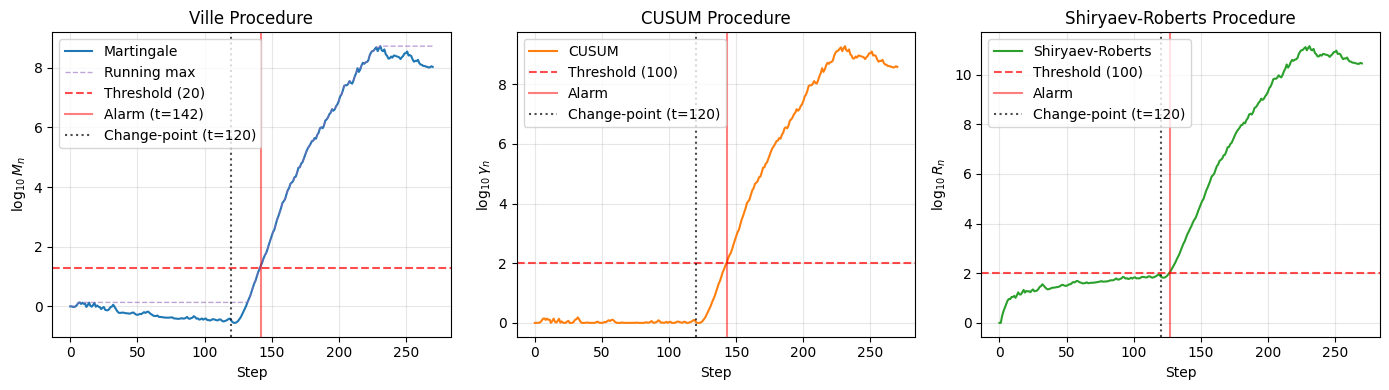

Ville rejected at observation 141 (threshold=20)
CUSUM statistic gamma=383234404.23, SR statistic R=28205050243.64


In [33]:

from online_cp import VilleWrapper, CUSUMWrapper, ShiryaevRobertsWrapper

# Same p-value stream as above, fed through three wrappers.
ville  = VilleWrapper(SimpleJumper(), threshold=20)
cusum  = CUSUMWrapper(SimpleJumper())
sr     = ShiryaevRobertsWrapper(SimpleJumper())

for p in mart_shift.p_values if hasattr(mart_shift, "p_values") else []:
    pass
# Re-generate the shifted p-values fresh to keep this cell self-contained.
cp_v = ConformalRidgeRegressor(a=1.0, rnd_state=0)
cp_v.learn_initial_training_set(X_s[:30], y_s[:30])
ps = []
for i in range(30, N_shift):
    ps.append(cp_v.compute_p_value(X_s[i], y_s[i])); cp_v.learn_one(X_s[i], y_s[i])

rejection = None
for i, p in enumerate(ps):
    ville.update(p); cusum.update(p); sr.update(p)
    if ville.rejected and rejection is None:
        rejection = i

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_detector(ville,  change_point=120, ax=axes[0])
plot_detector(cusum,  threshold=100, change_point=120, ax=axes[1])
plot_detector(sr,     threshold=100, change_point=120, ax=axes[2])
plt.tight_layout()
plt.show()

print(f"Ville rejected at observation {rejection} (threshold=20)")
print(f"CUSUM statistic gamma={cusum.gamma:.2f}, SR statistic R={sr.R:.2f}")



### 6.4 Sleeper martingales — unknown change-point location

`SleeperStayer` / `SleeperDrifter` maintain a pool of "sleeper" experts that
wake up continuously, so they detect change-points at *unknown* locations
without knowing the shift timescale.


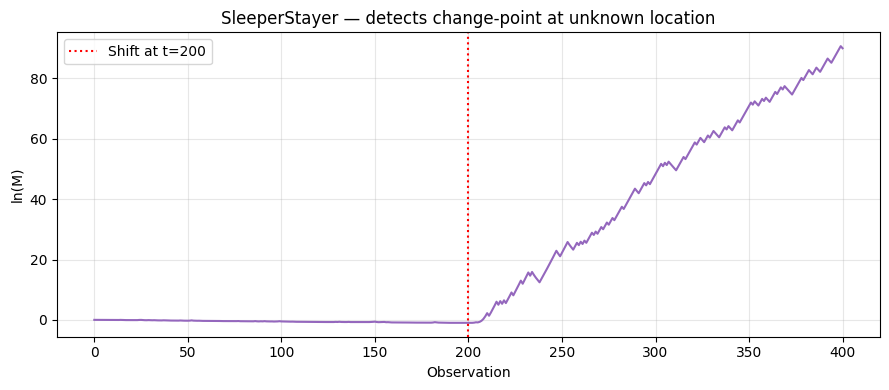

Final ln(M): 90.0


In [34]:

from online_cp import SleeperStayer, SleeperDrifter

# Pure p-value stream: 200 uniform (in-control) then 200 Beta(0.3,1) (shift).
rng_cp = np.random.default_rng(42)
p_stream = np.concatenate([rng_cp.uniform(size=200), rng_cp.beta(0.3, 1.0, size=200)])

mart_sleeper = SleeperStayer(R=0.01, G=5)
for p in p_stream:
    mart_sleeper.update(p)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mart_sleeper.log_martingale_values, color="tab:purple", lw=1.5)
ax.axvline(200, color="red", ls=":", lw=1.5, label="Shift at t=200")
ax.set_xlabel("Observation"); ax.set_ylabel("ln(M)")
ax.set_title("SleeperStayer — detects change-point at unknown location")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final ln(M): {mart_sleeper.logM:.1f}")



### 6.5 Pluggable betting strategies

A `PluginMartingale` wraps any **betting strategy** (a density estimator for
the p-values). The strategy's `bet(p)` is the density that multiplies into
$M_n$. Available strategies:

* `GaussianKDE` (default) — reflected Gaussian KDE.
* `BetaKernel` — Beta-kernel density (great near 0/1).
* `BetaMoments` / `BetaMLE` — Beta fit via method of moments / MLE.
* `PiecewiseConstantBetting(a, b)` — the canonical ALRW2 §9.2 bet.


In [35]:

from online_cp import PluginMartingale, GaussianKDE, BetaMoments, BetaMLE, PiecewiseConstantBetting

strategies = {
    "GaussianKDE (default)"   : PluginMartingale(GaussianKDE()),
    "BetaMoments"             : PluginMartingale(BetaMoments()),
    "BetaMLE"                 : PluginMartingale(BetaMLE()),
    "PiecewiseConstant(0.1,.3)": PluginMartingale(PiecewiseConstantBetting(a=0.1, b=0.3)),
}
for name, mart in strategies.items():
    for p in p_stream:
        mart.update(p)
    print(f"{name:24s} final ln(M) = {mart.logM:.2f}")


GaussianKDE (default)    final ln(M) = 58.80
BetaMoments              final ln(M) = 160.64
BetaMLE                  final ln(M) = 195.76
PiecewiseConstant(0.1,.3) final ln(M) = 70.91



**Martingales recap**

| family | classes |
|--------|---------|
| base | `SimpleJumper`, `SimpleMixtureMartingale`, `CompositeJumper`, `PluginMartingale` |
| change-point | `VilleWrapper`, `CUSUMWrapper`, `ShiryaevRobertsWrapper` |
| sleeper | `SleeperStayer`, `SleeperDrifter` |
| betting | `GaussianKDE`, `BetaKernel`, `BetaMoments`, `BetaMLE`, `PiecewiseConstantBetting` |

**Next**: §7 — once you trust your predictions, how do you turn them into
**decisions**?



---

## 7. How do I turn predictions into decisions? (Conformal predictive decision making)

> *I'm not predicting a value — I need to **act**: treat or wait, restock or
> not, which threshold to set. How do I choose the action that maximises
> expected **utility**, given my predictive uncertainty?*

A **utility function** $U(x, y, d) \to \mathbb{R}$ bundles a payoff rule with a
set of available decisions $\mathcal D$. Two engines compute expected utility
under uncertainty, and generic **criteria** (maximise, maximin, Hurwicz,
minimax-regret) select the action.


In [36]:

from online_cp import UtilityFunction, ConformalPredictiveDecisionMaker, RidgePredictionMachine
from online_cp import cps_expected_utilities, cps_decision, alpha_utility, alpha_regret

# A regression-decision problem: choose a target level d; U = -(y - d)^2.
decisions = [-20, -10, 0, 10, 20]
utility = UtilityFunction(fn=lambda x, y, d: -(y - d) ** 2, decisions=decisions)
print("Decision space:", decisions)
print("U(x, y=5, d=0)  =", utility(None, 5, 0))
print("U(x, y=5, d=10) =", utility(None, 5, 10))


Decision space: [-20, -10, 0, 10, 20]
U(x, y=5, d=0)  = -25
U(x, y=5, d=10) = -25



### 7.1 `ConformalPredictiveDecisionMaker` (Vovk & Bendtsen, Algorithm 1)

The exact algorithm trains **one CPS per decision** on utility-transformed
labels $\tilde y_d = U(x, y, d)$, then reads off expected utility from each
CPD and picks $\arg\max_d \mathbb E[U \mid x, d]$. The model is calibrated on
the *utility scale*, not raw labels.


In [37]:

dm = ConformalPredictiveDecisionMaker(utility, cps_class=RidgePredictionMachine, a=1.0)
dm.learn_initial_training_set(X[:80], y[:80])

tau = rng.uniform()
eu = dm.predict_expected_utilities(X[80], tau=tau)
best = dm.predict(X[80], tau=tau)
print(f"True y = {y[80]:.2f}\n")
print("Expected utilities per decision:")
for d, u in eu.items():
    marker = "  <-- optimal" if d == best else ""
    print(f"  d={d:+4d}:  E[U] = {u:+.2f}{marker}")

# A small evaluation loop: realise the utility of the chosen action.
dm2 = ConformalPredictiveDecisionMaker(utility, cps_class=RidgePredictionMachine, a=1.0)
dm2.learn_initial_training_set(X[:80], y[:80])
decisions_made, true_utilities = [], []
for i in range(80, 180):
    d_star = dm2.predict(X[i], tau=rng.uniform())
    decisions_made.append(d_star)
    true_utilities.append(utility(X[i], y[i], d_star))
    dm2.learn_one(X[i], y[i])

print("\nOver 100 test examples:")
print(f"  Mean realised utility : {np.mean(true_utilities):.2f}")
print(f"  Decision distribution : { {d: decisions_made.count(d) for d in decisions} }")


True y = 1.57

Expected utilities per decision:
  d= -20:  E[U] = -477.46
  d= -10:  E[U] = -143.35
  d=  +0:  E[U] = -4.93  <-- optimal
  d= +10:  E[U] = -61.80
  d= +20:  E[U] = -314.18

Over 100 test examples:
  Mean realised utility : -5.26
  Decision distribution : {-20: 0, -10: 0, 0: 99, 10: 1, 20: 0}



### 7.2 Decision criteria: `alpha_utility` vs `alpha_regret`

Under a *set* of possible outcomes (as a Venn pair gives you), you can choose
between optimistic and pessimistic criteria:

* $\alpha=0$ — **maximin** (worst-case, conservative)
* $\alpha=1$ — **maximax** (best-case, optimistic)
* $\alpha=0.5$ — midpoint

`alpha_regret` does the same with a regret (minimax) framing.

A key subtlety: **the two criteria only diverge on ambiguous inputs.** If the
worst-case ($p^0$) and best-case ($p^1$) hypotheses would lead to the *same*
action, then every $\alpha$ agrees. So to see them disagree we need (i) points
where the Venn pair genuinely spans the decision boundary, and (ii) a cost
structure where the two actions are close. On an easy, well-separated dataset
they will look identical — which is itself the reassuring behaviour you want.


In [38]:

# To see the criteria *actually diverge*, use an inherently ambiguous task
# (overlapping moons) so many points have a Venn pair straddling the boundary,
# and keep the treat/wait costs moderate so both actions stay competitive.
from online_cp import VennAbersPredictor, venn_decision
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

Xd, yd = make_moons(n_samples=500, noise=0.25, random_state=2)
Xd = StandardScaler().fit_transform(Xd)
screening = UtilityFunction(
    fn=lambda x, y, d: -4 if d == 'treat' else (-8 * y),
    decisions=['treat', 'wait'],
)
vap_d = VennAbersPredictor(scorer="ridge", a=1.0)
vap_d.learn_initial_training_set(Xd[:100], yd[:100])

rows = []
for i in range(100, 400):
    pred = vap_d.predict(Xd[i])
    d0  = venn_decision(pred, screening, Xd[i], criterion="utility", alpha=0.0)
    dm5 = venn_decision(pred, screening, Xd[i], criterion="utility", alpha=0.5)
    d1  = venn_decision(pred, screening, Xd[i], criterion="utility", alpha=1.0)
    rows.append((i - 100, int(yd[i]), pred.p0, pred.p1, d0, dm5, d1))
    vap_d.learn_one(Xd[i], yd[i])

header = ['ex', 'y', '(p0,p1)', 'maximin a=0', 'mid a=0.5', 'maximax a=1']
print(f"{header[0]:>3} {header[1]:>2}  {header[2]:>12}  {header[3]:>13}  {header[4]:>11}  {header[5]:>13}")
print("-" * 62)
shown_diff = shown_same = 0
for r in rows:
    diff = (r[4] != r[5]) or (r[4] != r[6])
    if diff and shown_diff < 8:
        tag = "   <-- criteria disagree"
        shown_diff += 1
    elif not diff and shown_same < 4:
        tag = ""
        shown_same += 1
    else:
        continue
    print(f"{r[0]:>3} {r[1]:>2}  ({r[2]:.2f},{r[3]:.2f})  {r[4]:>13}  {r[5]:>11}  {r[6]:>13}{tag}")

n_disagree = sum(1 for r in rows if r[4] != r[6])
print(f"maximin vs maximax disagree on {n_disagree}/{len(rows)} examples.")
print("Conservative (a=0) treats when even the worst case suggests it;")
print("optimistic (a=1) waits if the best case allows it.")


 ex  y       (p0,p1)    maximin a=0    mid a=0.5    maximax a=1
--------------------------------------------------------------
  0  1  (0.92,1.00)          treat        treat          treat
  1  1  (0.47,0.50)          treat         wait           wait   <-- criteria disagree
  2  0  (0.07,0.12)           wait         wait           wait
  3  1  (0.95,1.00)          treat        treat          treat
  4  0  (0.00,0.10)           wait         wait           wait
  8  0  (0.47,0.55)          treat        treat           wait   <-- criteria disagree
 11  1  (0.33,0.50)          treat         wait           wait   <-- criteria disagree
 23  1  (0.09,0.50)          treat         wait           wait   <-- criteria disagree
 28  0  (0.33,0.55)          treat         wait           wait   <-- criteria disagree
 40  0  (0.25,0.50)          treat         wait           wait   <-- criteria disagree
 56  0  (0.05,0.59)          treat         wait           wait   <-- criteria disagree
 93  0  (0.3


### 7.3 `cps_decision` — utility-driven decisions from a full CPD

For regression/CPS output you can skip the full decision-maker and just
compute expected utilities + pick an action on a single CPD:


In [39]:

cps_d = RidgePredictionMachine(a=1.0)
cps_d.learn_initial_training_set(X[:100], y[:100])
cpd_d = cps_d.predict(X[100])

eu = cps_expected_utilities(cpd_d, utility, X[100], tau=0.5)
best = cps_decision(cpd_d, utility, X[100], tau=0.5)
print(f"True y = {y[100]:.2f}, chosen d = {best}")
for d, u in eu.items():
    print(f"  d={d:+4d}: E[U]={u:+.2f}  {'<-- optimal' if d == best else ''}")


True y = 1.11, chosen d = 0
  d= -20: E[U]=-408.63  
  d= -10: E[U]=-105.63  
  d=  +0: E[U]=-0.66  <-- optimal
  d= +10: E[U]=-93.70  
  d= +20: E[U]=-384.76  



**Decision recap**

* `UtilityFunction(fn, decisions)` — the payoff + decision space.
* `ConformalPredictiveDecisionMaker(utility, cps_class=..., **cps_kwargs)` —
  full one-CPS-per-decision engine.
* `venn_decision(pred, utility, x, criterion, alpha)` — Venn-pair decisions.
* `cps_expected_utilities / cps_decision(cpd, utility, x, tau)` — CPD decisions.
* `alpha_utility / alpha_regret(expectations, alpha)` — Hurwicz / regret
  criteria operating on expectation tables.

**Next**: §8 — the production layer: pipelines, preprocessing, delayed labels,
and serialisation.



---

## 8. How do I deploy this in production? (Pipelines, evaluation & serialisation)

> *Real features need preprocessing, labels arrive late, and I need to persist
> the model overnight. How do all of these fit together **without breaking the
> validity guarantee**?* 

### 8.1 Conformal-safe pipelines & transformers

You can chain feature maps in front of *any* predictor using the `|` operator
(`Transformer | predictor -> Pipeline`), and combine maps with `+`
(concatenation). The pipeline re-exposes the full predictor API, so it is a
drop-in replacement in `progressive_val`.

Transformers come in three **validity regimes**:

* `mode="fixed"` — stateless maps (always safe): `FuncTransformer`, `Select`,
  `Discard`.
* `mode="frozen"` — parameters fit once on the initial training set, then held
  constant: `StandardScaler`, `MinMaxScaler`, `PCA`, `SVD`.
* `mode="bag"` — recomputed from the label-free augmented bag each step (exact
  finite-sample validity, no warm-up; slower).


In [40]:

from online_cp import Pipeline, FuncTransformer, Select, Discard
from online_cp import StandardScaler, MinMaxScaler, PCA, SVD

# Build a pipeline: scale (frozen) -> keep 2 cols -> polynomial feature -> ridge.
from online_cp import ConformalRidgeRegressor

def add_square(x):
    # Add a squared-feature column: [x1, x2] -> [x1, x2, x1^2, x2^2]
    return np.hstack([x, x ** 2])

pipe = (
    StandardScaler(mode="frozen")
    | Select([0, 1])
    | FuncTransformer(add_square)                # module-level function (serialisable)
    | ConformalRidgeRegressor(a=1.0)
)
pipe.learn_initial_training_set(X[:60], y[:60])
print("Pipeline interval:", pipe.predict(X[60], epsilon=0.1))
print("Pipeline p-value :", round(pipe.compute_p_value(X[60], y[60]), 4))

# Other stateless / frozen transformers you can compose:
# MinMaxScaler(feature_range=(0,1), mode="frozen")
# PCA(n_components=2, mode="frozen")
# SVD(n_components=2, mode="frozen")
# Discard([2,3])


Pipeline interval: ContinuousPredictionSet([(0.15571116557806897, 5.360941917041283)])
Pipeline p-value : 0.9555



### 8.2 The streaming evaluation API

`progressive_val` runs the full test-then-train loop and returns the final
metric. `iter_progressive_val` *yields* a snapshot every `step` — ideal for
learning curves. There are `_venn` variants for Venn predictors.


In [41]:

from online_cp.evaluate import progressive_val, iter_progressive_val, progressive_val_venn, iter_progressive_val_venn

# Learning curve via snapshots every 50 steps.
model_prod = ConformalRidgeRegressor(a=1.0)
model_prod.learn_initial_training_set(X[:50], y[:50])
metric_prod = ErrorRate() + IntervalWidth()
snapshots = list(iter_progressive_val(model_prod, X[50:], y[50:], epsilon=0.1, metric=metric_prod, step=50))
print("Learning curve (every 50 steps):")
for s in snapshots:
    print(f"  step {s['step']:3d}: error={s['ErrorRate']:.3f}  width={s['IntervalWidth']:.2f}")


Learning curve (every 50 steps):
  step  50: error=0.080  width=2.52
  step 100: error=0.100  width=2.32
  step 150: error=0.100  width=2.31
  step 200: error=0.090  width=2.27
  step 250: error=0.100  width=2.24



### 8.3 Delayed / missing labels

In production labels often arrive late, or not at all. The `learn` argument of
every evaluation function controls *when* the model updates — pass a predicate
`(i, x, y) -> bool`. The coverage guarantee still holds for the examples you
actually train on. A `delay` argument shifts label availability by a fixed
number of steps.


In [42]:

# 100% vs 50% label availability.
model_full = ConformalRidgeRegressor(a=1.0)
model_full.learn_initial_training_set(X[:50], y[:50])
m_full = ErrorRate() + IntervalWidth()
progressive_val(model_full, X[50:300], y[50:300], epsilon=0.1, metric=m_full)

model_half = ConformalRidgeRegressor(a=1.0)
model_half.learn_initial_training_set(X[:50], y[:50])
m_half = ErrorRate() + IntervalWidth()
progressive_val(
    model_half, X[50:300], y[50:300], epsilon=0.1, metric=m_half,
    learn=lambda i, x, y: i % 2 == 0,          # only learn every other example
)

print(f"100% labels: error={m_full['ErrorRate'].get():.3f}  width={m_full['IntervalWidth'].get():.2f}")
print(f" 50% labels: error={m_half['ErrorRate'].get():.3f}  width={m_half['IntervalWidth'].get():.2f}")
print("\n-> Coverage guarantee still holds with fewer labels; intervals are wider.")


100% labels: error=0.100  width=2.24
 50% labels: error=0.100  width=2.36

-> Coverage guarantee still holds with fewer labels; intervals are wider.



### 8.4 Serialisation — save and load a model mid-stream

Every model (and every `Pipeline`) supports `save(path)` / `Class.load(path)`.
The exact RNG stream position is captured, so predictions after loading are
**bit-for-bit identical** to the original. Registered callables (see §2.4)
round-trip too.


In [43]:

import tempfile, os

with tempfile.TemporaryDirectory() as td:
    fp = os.path.join(td, "pipeline.joblib")
    pipe.save(fp)                       # pipe built in 8.1
    pipe2 = Pipeline.load(fp)

    # Same input -> identical predictions after a save/load round-trip.
    a = pipe.predict(X[70], epsilon=0.1)
    b = pipe2.predict(X[70], epsilon=0.1)
    print("Round-trip predictions identical:", np.allclose(a.to_single_interval(), b.to_single_interval()))

# Any single predictor saves/loads the same way:
# model.save("model.joblib") ; model = ConformalRidgeRegressor.load("model.joblib")


Round-trip predictions identical: True



### 8.5 Capstone — a complete production workflow

Everything combined: permute data → **pipeline** (scale + feature engineering) →
**conformal model** → **streaming evaluation** with snapshots → **save** the
warm model. This is the shape of a real deployment loop.

> **Note the low error:** California Housing is highly predictable by Ridge,
> so the conformal error rate (≈ 2–3%) comfortably *beats* the nominal
> $\varepsilon = 0.05$ — validity guarantees are one-sided ($\le\ \varepsilon$),
> so being well under target is expected and desirable, not a bug.


In [44]:

from online_cp import Pipeline, StandardScaler, Discard, ConformalRidgeRegressor
from online_cp.evaluate import iter_progressive_val

# 1) Realistic feature prep: standardise, drop two noisy columns, scale to [0,1].
capstone = (
    StandardScaler(mode="frozen")
    | Discard([2, 5])          # drop two columns (illustrative)
    | MinMaxScaler(feature_range=(0, 1), mode="frozen")
    | ConformalRidgeRegressor(a=1.0)
)

# 2) Warm up, then stream the rest with learning-curve snapshots.
capstone.learn_initial_training_set(X[:80], y[:80])
m = ErrorRate() + IntervalWidth() + WinklerScore()
snapshots = list(iter_progressive_val(capstone, X[80:], y[80:], epsilon=0.05, metric=m, step=60))
for s in snapshots:
    print(f"  step {s['step']:3d}: error={s['ErrorRate']:.3f}  width={s['IntervalWidth']:.2f}  winkler={s['WinklerScore']:.2f}")

# 3) Persist the warm model for the next day's stream.
import tempfile, os
with tempfile.TemporaryDirectory() as td:
    fp = os.path.join(td, "capstone.joblib")
    capstone.save(fp)
    capstone_loaded = Pipeline.load(fp)
    iv = capstone_loaded.predict(X[-1], epsilon=0.05)
    print(f"\nLoaded model predicts [{iv.lower:.3f}, {iv.upper:.3f}] for a fresh example.")


  step  60: error=0.017  width=3.77  winkler=3.98
  step 120: error=0.033  width=3.65  winkler=4.01
  step 180: error=0.033  width=3.50  winkler=3.81

Loaded model predicts [1.003, 4.296] for a fresh example.



**Composable metrics — the full table**

| metric | for | meaning |
|--------|-----|---------|
| `ErrorRate` | all | fraction outside the prediction set (the guarantee) |
| `IntervalWidth` | regression | average interval width (sharpness) |
| `WinklerScore` | regression | proper interval scoring rule |
| `SetSize` | classification | average number of labels in the set |
| `ObservedExcess` | classification | # false labels in the set |
| `ObservedFuzziness` | classification | calibration via p-values |
| `CRPS` / `TruncatedCRPS` / `ConformalCRPS` | CPS | probability-score (lower = better) |
| `BrierScore` / `LogLoss` | Venn | proper probabilistic scoring |
| `Width` | Venn | sharpness of the multiprobability |
| `CalibrationError` | Venn | expected calibration error (ECE) |

**Next**: §9 — the full API at a glance.



---

## 9. Summary & API at a glance

### The universal contract

```python
model = <any conformal predictor>()
model.learn_initial_training_set(X_train, y_train)   # warm-up

interval = model.predict(x_new, epsilon=0.1)         # single level -> prediction set
result   = model.predict(x_new, epsilon=[0.05,0.1])  # multi-level (nested sets)
p        = model.compute_p_value(x_new, y_new)       # conformal p-value
model.learn_one(x_new, y_new)                        # online update
```

### Models

| category | classes |
|----------|---------|
| **Regressors** | `ConformalRidgeRegressor`, `KernelConformalRidgeRegressor`, `ConformalLassoRegressor`, `ConformalNearestNeighboursRegressor` |
| **Classifiers** | `ConformalNearestNeighboursClassifier`, `ConformalSupportVectorMachine` |
| **Venn** | `VennAbersPredictor`, `NearestNeighboursVennPredictor`, `MondrianVennPredictor`, `MulticlassVennPrediction` |
| **Mondrian** | `MondrianConformalRegressor`, `MondrianConformalClassifier`, `ConformalMondrianTree{Regressor,Classifier}`, `ConformalMondrianForest{Regressor,Classifier}`, `MondrianTree` |
| **CPS** | `RidgePredictionMachine`, `KernelRidgePredictionMachine`, `NearestNeighboursPredictionMachine`, `DempsterHillConformalPredictiveSystem`, `MondrianTreePredictionMachine` |
| **Decision** | `ConformalPredictiveDecisionMaker`, `UtilityFunction`, `venn_decision`, `cps_decision`, `alpha_utility`, `alpha_regret` |
| **Martingales** | `SimpleJumper`, `SimpleMixtureMartingale`, `CompositeJumper`, `PluginMartingale`, `SleeperStayer`, `SleeperDrifter` |
| **Wrappers** | `VilleWrapper`, `CUSUMWrapper`, `ShiryaevRobertsWrapper` |
| **Betting** | `GaussianKDE`, `BetaKernel`, `BetaMoments`, `BetaMLE`, `PiecewiseConstantBetting` |
| **Kernels** | `GaussianKernel`, `LinearKernel`, `PolynomialKernel`, `PeriodicKernel`, `LinearCombinationKernel`, `ProductKernel`, `CustomKernel` |
| **Pipeline** | `Pipeline`, `Transformer`, `FuncTransformer`, `Select`, `Discard`, `TransformerUnion`, `StandardScaler`, `MinMaxScaler`, `PCA`, `SVD` |

### Plotting

| function | shows |
|----------|-------|
| `plot_coverage` | running coverage vs nominal level |
| `plot_intervals` | prediction intervals vs true values |
| `plot_set_sizes` | running average prediction set size |
| `plot_martingale` | martingale trajectory (log scale) |
| `plot_detector` | Ville / CUSUM / SR statistic with alarm markers |
| `plot_pit_histogram` | PIT histogram — calibration check for CPDs |
| `plot_reliability_diagram` | predicted vs observed frequency |
| `plot_reliability_diagram_venn` | Venn-Abers calibration guarantee |
| `plot_sharpness` | distribution of multiprobability widths |
| `plot_calibration_conditional` | per-group reliability diagrams |

### Looking for **inductive (split)** conformal prediction?

This package focuses on **online (transductive)** conformal prediction. If you
have a fixed pre-trained model plus a held-out calibration set, the
[`crepes`](https://github.com/henrikbostrom/crepes) package is an excellent
complement.

### References

* Vovk, Gammerman, Shafer. *Algorithmic Learning in a Random World* (2nd ed.). Springer, 2022.
* Vovk & Bendtsen. *Conformal predictive decision making.* COPA / PMLR 91, 2018.
* Lei. *Fast exact conformalization of the Lasso using piecewise linear homotopy.* Biometrika, 2019.
* Hallberg Szabadv\u00e1ry, L\u00f6fstr\u00f6m & Matela. *online-cp: a Python package for online conformal prediction...* PMLR v266, 2025.
